<a href="https://colab.research.google.com/github/youngbean0519/Self-Project/blob/main/notebooks/08_textcnn_bilstm_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. 환경 설정

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import sys

PROJECT_DIR = Path("/content/Self-Project")
SRC_DIR = PROJECT_DIR / "src"

if not PROJECT_DIR.exists():
    !git clone https://github.com/youngbean0519/Self-Project.git

!pip install -q sentencepiece kiwipiepy

if str(PROJECT_DIR) not in sys.path:
    sys.path.append(str(PROJECT_DIR))

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

Cloning into 'Self-Project'...
remote: Enumerating objects: 92, done.
remote: Counting objects: 100% (92/92), done.
remote: Compressing objects: 100% (74/74), done.
remote: Total 92 (delta 34), reused 60 (delta 10), pack-reused 0 (from 0)
Receiving objects: 100% (92/92), 621.28 KiB | 20.71 MiB/s, done.
Resolving deltas: 100% (34/34), done.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 20.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 55.7 MB/s eta 0:00:00


In [ ]:
import copy
import hashlib
import json
import math
import random
import time

import numpy as np
import pandas as pd
import sentencepiece as spm
import torch
import torch.nn as nn

from kiwipiepy import Kiwi
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    hamming_loss,
    precision_score,
    recall_score
)
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)
from torch.utils.data import Dataset, DataLoader

import preprocessing.text as text_preprocessing
import utils.labels as utils_labels

DATA_DIR = Path("/content/drive/MyDrive/26_KOTE/data")
ARTIFACT_DIR = Path("/content/drive/MyDrive/26_KOTE/artifacts/week8_tuning")
WEEK6_SP = Path("/content/drive/MyDrive/26_KOTE/artifacts/week6_textcnn/sentencepiece/kote_sp.model")

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LABEL_NAMES = utils_labels.LABELS
NUM_LABELS = 44

assert len(LABEL_NAMES) == NUM_LABELS
assert WEEK6_SP.exists(), f"기존 토크나이저 없음: {WEEK6_SP}"

print("Device:", DEVICE)
if DEVICE.type == "cuda":
  print("GPU:", torch.cuda.get_device_name(0))

def set_seed(seed):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)

  if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

  torch.backends.cudnn.deterministic = True
  torch.backends.cudnn.benchmark = False

def save_json(data, path):
  with open(path, "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, indent=2)

def config_id(config):
  text = json.dumps(config, sort_keys=True)
  return hashlib.sha256(text.encode()).hexdigest()[:12]

Device: cuda
GPU: NVIDIA L4


# 2. 데이터와 전처리 준비

In [ ]:
def load_split(name):
    return pd.read_csv(
        DATA_DIR / f"{name}.tsv",
        sep="\t",
        header=None,
        names=["id", "text", "labels"]
    )

train_df = load_split("train")
val_df = load_split("val")

def make_labels(df):
    targets = np.zeros((len(df), NUM_LABELS), dtype=np.float32)

    for i, value in enumerate(df["labels"].astype(str)):
        indices = [
            int(x.strip()) for x in value.split(",") if x.strip()
        ]
        targets[i, indices] = 1.0

    return targets

y_train = make_labels(train_df)
y_val = make_labels(val_df)

PREPROCESSING = {
    "repeat": {
        "normalize_repeat": True,
        "remove_symbols": False
    },
    "minimal": {
        "normalize_repeat": False,
        "remove_symbols": False
    },
    "repeat_symbols": {
        "normalize_repeat": True,
        "remove_symbols": True
    }
}

TEXT_CACHE = {}

def get_texts(mode):
    if mode not in TEXT_CACHE:
        kwargs = PREPROCESSING[mode]

        def convert(df):
            return df["text"].fillna("").astype(str).apply(
                lambda text: text_preprocessing.preprocess_text(
                    text, **kwargs
                )
            ).tolist()

        TEXT_CACHE[mode] = (convert(train_df), convert(val_df))

    return TEXT_CACHE[mode]

print("Train:", train_df.shape, y_train.shape)
print("Validation:", val_df.shape, y_val.shape)

Train: (40000, 3) (40000, 44)
Validation: (5000, 3) (5000, 44)


# 3. 토크나이저와 입력 데이터 구성

In [ ]:
from collections import Counter

class SPTokenizer:
    def __init__(self, path):
        self.sp = spm.SentencePieceProcessor(model_file=str(path))
        self.pad_id = self.sp.pad_id()
        self.unk_id = self.sp.unk_id()
        self.vocab_size = self.sp.get_piece_size()

    def encode(self, text):
        return self.sp.encode(str(text), out_type=int)


class KiwiTokenizer:
    def __init__(self, vocab_path):
        self.kiwi = Kiwi()
        self.vocab = json.loads(
            Path(vocab_path).read_text(encoding="utf-8")
        )
        self.pad_id = 0
        self.unk_id = 1
        self.vocab_size = len(self.vocab)

    def pieces(self, text):
        return [
            f"{token.form}/{token.tag}"
            for token in self.kiwi.tokenize(str(text))
        ]

    def encode(self, text):
        return [
            self.vocab.get(piece, self.unk_id)
            for piece in self.pieces(text)
        ]


TOKENIZER_CACHE = {}
INPUT_CACHE = {}

def get_tokenizer(config):
    key = (
        config["preprocessing"],
        config["tokenizer"],
        config["vocab_size"]
    )

    if key in TOKENIZER_CACHE:
        return TOKENIZER_CACHE[key]

    mode, kind, vocab_size = key
    train_texts, _ = get_texts(mode)

    folder = (
        ARTIFACT_DIR / "tokenizers" /
        f"{mode}_{kind}_{vocab_size}"
    )
    folder.mkdir(parents=True, exist_ok=True)

    if key == ("repeat", "unigram", 8000):
        tokenizer = SPTokenizer(WEEK6_SP)

    elif kind in {"unigram", "bpe"}:
        model_path = folder / "tokenizer.model"

        if not model_path.exists():
            corpus_path = folder / "train.txt"
            with open(corpus_path, "w", encoding="utf-8") as f:
                for text in train_texts:
                    text = str(text).replace("\n", " ").strip()
                    if text:
                        f.write(text + "\n")

            spm.SentencePieceTrainer.train(
                input=str(corpus_path),
                model_prefix=str(folder / "tokenizer"),
                model_type=kind,
                vocab_size=vocab_size,
                character_coverage=1.0,
                pad_id=0,
                unk_id=1,
                bos_id=-1,
                eos_id=-1,
                hard_vocab_limit=False
            )

        tokenizer = SPTokenizer(model_path)

    elif kind == "kiwi":
        vocab_path = folder / "vocab.json"

        if not vocab_path.exists():
            kiwi = Kiwi()
            counts = Counter()

            for text in train_texts:
                counts.update(
                    f"{token.form}/{token.tag}"
                    for token in kiwi.tokenize(str(text))
                )

            vocab = {"<pad>": 0, "<unk>": 1}

            for piece, _ in counts.most_common(vocab_size - 2):
                if piece not in vocab:
                    vocab[piece] = len(vocab)

            save_json(vocab, vocab_path)

        tokenizer = KiwiTokenizer(vocab_path)

    else:
        raise ValueError(kind)

    assert tokenizer.pad_id == 0
    TOKENIZER_CACHE[key] = tokenizer
    return tokenizer


def get_encoded_inputs(config):
    key = (
        config["preprocessing"],
        config["tokenizer"],
        config["vocab_size"]
    )

    if key not in INPUT_CACHE:
        tokenizer = get_tokenizer(config)
        train_texts, val_texts = get_texts(config["preprocessing"])

        train_ids = [tokenizer.encode(x) for x in train_texts]
        val_ids = [tokenizer.encode(x) for x in val_texts]

        INPUT_CACHE[key] = (tokenizer, train_ids, val_ids)

    return INPUT_CACHE[key]


def input_statistics(ids_list, tokenizer, max_len):
    lengths = np.array([len(ids) for ids in ids_list])
    total = sum(len(ids) for ids in ids_list)
    unknown = sum(
        sum(token == tokenizer.unk_id for token in ids)
        for ids in ids_list
    )

    return {
        "mean_tokens": float(lengths.mean()),
        "p95": float(np.percentile(lengths, 95)),
        "p99": float(np.percentile(lengths, 99)),
        "truncation_rate": float((lengths > max_len).mean()),
        "unk_ratio": unknown / max(total, 1),
        "empty_count": int((lengths == 0).sum())
    }


class EncodedDataset(Dataset):
    def __init__(self, ids_list, labels, max_len, unk_id=1):
        self.ids_list = ids_list
        self.labels = labels
        self.max_len = max_len
        self.unk_id = unk_id

    def __len__(self):
        return len(self.ids_list)

    def __getitem__(self, index):
        ids = self.ids_list[index][:self.max_len]

        # 빈 문장을 PAD로만 표현하지 않음
        if not ids:
            ids = [self.unk_id]

        length = len(ids)
        padded = ids + [0] * (self.max_len - length)

        return (
            torch.tensor(padded, dtype=torch.long),
            torch.tensor(length, dtype=torch.long),
            torch.tensor(self.labels[index], dtype=torch.float32)
        )

# 4. 두 모델과 변경 가능한 설정

In [ ]:
class TextCNN(nn.Module):
    def __init__(self, vocab_size, config):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, config["embed_dim"], padding_idx=0
        )
        self.kernel_sizes = config["kernel_sizes"]
        self.mask_padding = config["cnn_mask"]

        self.convs = nn.ModuleList([
            nn.Conv1d(
                config["embed_dim"],
                config["num_filters"],
                kernel_size=k
            )
            for k in self.kernel_sizes
        ])

        self.dropout = nn.Dropout(config["dropout"])
        self.classifier = nn.Linear(
            config["num_filters"] * len(self.kernel_sizes),
            NUM_LABELS
        )

    def forward(self, input_ids, lengths):
        x = self.embedding(input_ids).transpose(1, 2)
        outputs = []

        for conv in self.convs:
            features = torch.relu(conv(x))

            if self.mask_padding:
                starts = torch.arange(
                    features.size(2), device=features.device
                )[None, :]

                valid = starts < lengths.to(features.device)[:, None]
                features = features.masked_fill(
                    ~valid[:, None, :],
                    torch.finfo(features.dtype).min
                )

            outputs.append(features.max(dim=2).values)

        features = torch.cat(outputs, dim=1)
        return self.classifier(self.dropout(features))


class BiLSTM(nn.Module):
    def __init__(self, vocab_size, config):
        super().__init__()

        self.pooling = config["pooling"]

        self.embedding = nn.Embedding(
            vocab_size, config["embed_dim"], padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=config["embed_dim"],
            hidden_size=config["hidden_dim"],
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        feature_dim = config["hidden_dim"] * 2
        if self.pooling == "meanmax":
            feature_dim *= 2

        self.dropout = nn.Dropout(config["dropout"])
        self.classifier = nn.Linear(feature_dim, NUM_LABELS)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, (hidden, _) = self.lstm(packed)

        if self.pooling == "last":
            features = torch.cat(
                [hidden[-2], hidden[-1]], dim=1
            )

        else:
            output, _ = pad_packed_sequence(
                packed_output, batch_first=True
            )

            mask = (
                torch.arange(output.size(1), device=output.device)[None, :]
                < lengths.to(output.device)[:, None]
            )

            maximum = output.masked_fill(
                ~mask[:, :, None],
                torch.finfo(output.dtype).min
            ).max(dim=1).values

            if self.pooling == "max":
                features = maximum

            elif self.pooling == "meanmax":
                mean = (
                    output.masked_fill(~mask[:, :, None], 0).sum(dim=1)
                    / lengths.to(output.device)[:, None]
                )
                features = torch.cat([mean, maximum], dim=1)

            else:
                raise ValueError(self.pooling)

        return self.classifier(self.dropout(features))


BASE_CONFIG = {
    "model": "textcnn",
    "seed": 42,
    "preprocessing": "repeat",
    "tokenizer": "unigram",
    "vocab_size": 8000,
    "max_len": 120,
    "embed_dim": 200,
    "num_filters": 128,
    "kernel_sizes": [2, 3, 4, 5],
    "cnn_mask": False,
    "hidden_dim": 128,
    "pooling": "last",
    "dropout": 0.3,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "batch_size": 128,
    "max_epochs": 15,
    "patience": 3,
    "loss": "bce"
}

BASELINES = {}

for model_name in ["textcnn", "bilstm"]:
    config = copy.deepcopy(BASE_CONFIG)
    config["model"] = model_name
    BASELINES[model_name] = config

# 5. 공통 평가 함수

In [ ]:
THRESHOLDS = np.round(np.arange(0.10, 0.61, 0.05), 2)

def classification_metrics(labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(np.int32)

    return {
        "micro_f1": float(f1_score(
            labels, predictions, average="micro", zero_division=0
        )),
        "macro_f1": float(f1_score(
            labels, predictions, average="macro", zero_division=0
        )),
        "hamming_loss": float(hamming_loss(labels, predictions)),
        "precision_micro": float(precision_score(
            labels, predictions, average="micro", zero_division=0
        )),
        "recall_micro": float(recall_score(
            labels, predictions, average="micro", zero_division=0
        )),
        "predicted_labels_per_sample": float(
            predictions.sum(axis=1).mean()
        )
    }


def threshold_search(labels, probabilities, thresholds=THRESHOLDS):
    rows = []

    for threshold in thresholds:
        rows.append({
            "threshold": float(threshold),
            **classification_metrics(labels, probabilities, threshold)
        })

    table = pd.DataFrame(rows)
    best = table.loc[table["micro_f1"].idxmax()].to_dict()
    return table, best


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    count = 0
    all_probabilities = []
    all_labels = []

    for input_ids, lengths, labels in loader:
        input_ids = input_ids.to(DEVICE)
        labels = labels.to(DEVICE)

        logits = model(input_ids, lengths)
        loss = criterion(logits, labels)

        total_loss += loss.item() * len(labels)
        count += len(labels)

        all_probabilities.append(torch.sigmoid(logits).cpu().numpy())
        all_labels.append(labels.cpu().numpy())

    return (
        total_loss / count,
        np.vstack(all_probabilities),
        np.vstack(all_labels)
    )


def labelwise_table(labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(np.int32)

    return pd.DataFrame({
        "label_id": np.arange(NUM_LABELS),
        "label": LABEL_NAMES,
        "support": labels.sum(axis=0).astype(int),
        "predicted": predictions.sum(axis=0),
        "precision": precision_score(
            labels, predictions, average=None, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, average=None, zero_division=0
        ),
        "f1": f1_score(
            labels, predictions, average=None, zero_division=0
        )
    })

# 6. 학습 저장 실험 비교 함수

In [ ]:
def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def run_experiment(config, force=False):
    config = copy.deepcopy(config)
    run_id = config_id(config)

    run_dir = ARTIFACT_DIR / "runs" / run_id
    run_dir.mkdir(parents=True, exist_ok=True)
    summary_path = run_dir / "summary.json"

    if summary_path.exists() and not force:
        return json.loads(summary_path.read_text(encoding="utf-8"))

    tokenizer, train_ids, val_ids = get_encoded_inputs(config)

    train_stats = input_statistics(
        train_ids, tokenizer, config["max_len"]
    )
    val_stats = input_statistics(
        val_ids, tokenizer, config["max_len"]
    )

    train_dataset = EncodedDataset(
        train_ids, y_train, config["max_len"], tokenizer.unk_id
    )
    val_dataset = EncodedDataset(
        val_ids, y_val, config["max_len"], tokenizer.unk_id
    )

    set_seed(config["seed"])

    generator = torch.Generator().manual_seed(config["seed"])

    train_loader = DataLoader(
        train_dataset,
        batch_size=config["batch_size"],
        shuffle=True,
        generator=generator,
        num_workers=0
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=config["batch_size"],
        shuffle=False,
        num_workers=0
    )

    if config["model"] == "textcnn":
        model = TextCNN(tokenizer.vocab_size, config).to(DEVICE)
    else:
        model = BiLSTM(tokenizer.vocab_size, config).to(DEVICE)

    if config["loss"] == "weighted_bce":
        positives = y_train.sum(axis=0)
        negatives = len(y_train) - positives

        weights = np.minimum(
            5.0, np.sqrt(negatives / np.maximum(positives, 1))
        )
        criterion = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                weights, dtype=torch.float32, device=DEVICE
            )
        )
    else:
        criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"]
    )

    best_score = -1
    best_epoch = 0
    patience_counter = 0
    history = []
    checkpoint_path = run_dir / "best.pt"

    save_json(config, run_dir / "config.json")

    synchronize()
    start = time.perf_counter()

    for epoch in range(1, config["max_epochs"] + 1):
        model.train()
        total_loss = 0.0
        count = 0

        for input_ids, lengths, labels in train_loader:
            input_ids = input_ids.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            logits = model(input_ids, lengths)
            loss = criterion(logits, labels)

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * len(labels)
            count += len(labels)

        val_loss, probabilities, labels = evaluate(
            model, val_loader, criterion
        )
        _, best = threshold_search(labels, probabilities)

        history.append({
            "epoch": epoch,
            "train_loss": total_loss / count,
            "val_loss": val_loss,
            **best
        })

        print(
            f"{run_id} | {config['model']} | epoch {epoch:02d} | "
            f"train {total_loss / count:.4f} | val {val_loss:.4f} | "
            f"micro {best['micro_f1']:.4f} | "
            f"macro {best['macro_f1']:.4f} | "
            f"threshold {best['threshold']:.2f}"
        )

        if best["micro_f1"] > best_score:
            best_score = best["micro_f1"]
            best_epoch = epoch
            patience_counter = 0
            torch.save(model.state_dict(), checkpoint_path)

        else:
            patience_counter += 1

            if patience_counter >= config["patience"]:
                break

    synchronize()
    elapsed = time.perf_counter() - start

    model.load_state_dict(torch.load(
        checkpoint_path, map_location=DEVICE, weights_only=True
    ))

    val_loss, probabilities, labels = evaluate(
        model, val_loader, criterion
    )
    threshold_table, best = threshold_search(labels, probabilities)

    ap_micro = float(average_precision_score(
        labels, probabilities, average="micro"
    ))
    ap_macro = float(average_precision_score(
        labels, probabilities, average="macro"
    ))

    pd.DataFrame(history).to_csv(
        run_dir / "history.csv", index=False
    )
    threshold_table.to_csv(
        run_dir / "thresholds.csv", index=False
    )
    labelwise_table(
        labels, probabilities, best["threshold"]
    ).to_csv(
        run_dir / "labelwise.csv", index=False, encoding="utf-8-sig"
    )
    np.savez_compressed(
        run_dir / "validation_predictions.npz",
        probabilities=probabilities,
        labels=labels
    )

    summary = {
        "run_id": run_id,
        "config": config,
        **best,
        "ap_micro": ap_micro,
        "ap_macro": ap_macro,
        "val_loss": val_loss,
        "best_epoch": best_epoch,
        "epochs_run": len(history),
        "training_seconds": elapsed,
        "parameters": sum(p.numel() for p in model.parameters()),
        "actual_vocab_size": tokenizer.vocab_size,
        "train_input_stats": train_stats,
        "val_input_stats": val_stats,
        "device": str(DEVICE),
        "gpu": (
            torch.cuda.get_device_name(0)
            if DEVICE.type == "cuda" else None
        ),
        "test_evaluated": False
    }

    save_json(summary, summary_path)

    del model, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return summary


def result_table(results):
    rows = []

    for result in results:
        rows.append({
            "run_id": result["run_id"],
            **result["config"],
            **{
                key: result[key]
                for key in [
                    "micro_f1", "macro_f1", "hamming_loss",
                    "ap_micro", "threshold", "best_epoch",
                    "training_seconds", "parameters"
                ]
            }
        })

    return pd.DataFrame(rows).sort_values(
        "micro_f1", ascending=False
    ).reset_index(drop=True)


STAGE_LOG = []

def compare_candidates(base, changes, stage):
    configs = [copy.deepcopy(base)]

    for change in changes:
        candidate = copy.deepcopy(base)
        candidate.update(change)
        configs.append(candidate)

    # 동일 설정 중복 제거
    configs = {config_id(c): c for c in configs}
    results = [run_experiment(c) for c in configs.values()]

    table = result_table(results)
    print("\nStage:", stage)
    display(table)

    stage_record = {
        "stage": stage,
        "base": base,
        "run_ids": [r["run_id"] for r in results]
    }
    STAGE_LOG.append(stage_record)

    save_json(STAGE_LOG, ARTIFACT_DIR / "stage_log.json")

    table.to_csv(
        ARTIFACT_DIR / f"{stage}.csv",
        index=False,
        encoding="utf-8-sig"
    )

    winner = max(results, key=lambda r: r["micro_f1"])
    return copy.deepcopy(winner["config"]), results

# 7. 기존 조건 재현

In [ ]:
baseline_results = {
    name: run_experiment(config)
    for name, config in BASELINES.items()
}

display(result_table(list(baseline_results.values())))

CURRENT = copy.deepcopy(BASELINES)

d982e9060491 | textcnn | epoch 01 | train 0.4226 | val 0.3830 | micro 0.4930 | macro 0.3302 | threshold 0.25
d982e9060491 | textcnn | epoch 02 | train 0.3756 | val 0.3677 | micro 0.5154 | macro 0.3570 | threshold 0.25
d982e9060491 | textcnn | epoch 03 | train 0.3532 | val 0.3644 | micro 0.5253 | macro 0.3767 | threshold 0.25
d982e9060491 | textcnn | epoch 04 | train 0.3386 | val 0.3575 | micro 0.5333 | macro 0.3899 | threshold 0.25
d982e9060491 | textcnn | epoch 05 | train 0.3253 | val 0.3554 | micro 0.5398 | macro 0.3998 | threshold 0.25
d982e9060491 | textcnn | epoch 06 | train 0.3134 | val 0.3595 | micro 0.5334 | macro 0.4011 | threshold 0.25
d982e9060491 | textcnn | epoch 07 | train 0.3025 | val 0.3587 | micro 0.5366 | macro 0.4064 | threshold 0.25
d982e9060491 | textcnn | epoch 08 | train 0.2932 | val 0.3599 | micro 0.5379 | macro 0.4140 | threshold 0.25
31a7f4b7464b | bilstm | epoch 01 | train 0.4249 | val 0.3812 | micro 0.4931 | macro 0.3033 | threshold 0.25
31a7f4b7464b | bilst

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,31a7f4b7464b,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.547887,0.405174,0.177709,0.572195,0.30,5,59.159789,1949228
1,d982e9060491,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.539820,0.399788,0.188373,0.556880,0.25,5,33.157337,1981484


# 8. 학습 조건 조정

In [ ]:
for name in CURRENT:
    CURRENT[name], _ = compare_candidates(
        CURRENT[name],
        [{"lr": 3e-4}, {"lr": 3e-3}],
        f"{name}_01_learning_rate"
    )

    CURRENT[name], _ = compare_candidates(
        CURRENT[name],
        [{"dropout": 0.5}],
        f"{name}_02_dropout"
    )

    CURRENT[name], _ = compare_candidates(
        CURRENT[name],
        [{"batch_size": 64}],
        f"{name}_03_batch_size"
    )

save_json(CURRENT, ARTIFACT_DIR / "current_after_training.json")

28fbe017c86e | textcnn | epoch 01 | train 0.4442 | val 0.4131 | micro 0.4320 | macro 0.2655 | threshold 0.20
28fbe017c86e | textcnn | epoch 02 | train 0.4058 | val 0.3917 | micro 0.4771 | macro 0.2921 | threshold 0.25
28fbe017c86e | textcnn | epoch 03 | train 0.3832 | val 0.3799 | micro 0.4973 | macro 0.3225 | threshold 0.25
28fbe017c86e | textcnn | epoch 04 | train 0.3685 | val 0.3729 | micro 0.5084 | macro 0.3419 | threshold 0.25
28fbe017c86e | textcnn | epoch 05 | train 0.3570 | val 0.3680 | micro 0.5164 | macro 0.3650 | threshold 0.25
28fbe017c86e | textcnn | epoch 06 | train 0.3477 | val 0.3651 | micro 0.5214 | macro 0.3748 | threshold 0.25
28fbe017c86e | textcnn | epoch 07 | train 0.3398 | val 0.3615 | micro 0.5269 | macro 0.3747 | threshold 0.25
28fbe017c86e | textcnn | epoch 08 | train 0.3334 | val 0.3605 | micro 0.5290 | macro 0.3817 | threshold 0.25
28fbe017c86e | textcnn | epoch 09 | train 0.3281 | val 0.3585 | micro 0.5330 | macro 0.3858 | threshold 0.25
28fbe017c86e | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,d982e9060491,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.539820,0.399788,0.188373,0.556880,0.25,5,33.157337,1981484
1,28fbe017c86e,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.538894,0.404621,0.184945,0.555807,0.25,15,58.054078,1981484
2,c287d2bf124f,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.538351,0.420872,0.188032,0.558485,0.25,5,30.892069,1981484


6fbbd92e055b | textcnn | epoch 01 | train 0.4338 | val 0.3890 | micro 0.4838 | macro 0.3150 | threshold 0.25
6fbbd92e055b | textcnn | epoch 02 | train 0.3878 | val 0.3721 | micro 0.5089 | macro 0.3416 | threshold 0.25
6fbbd92e055b | textcnn | epoch 03 | train 0.3679 | val 0.3657 | micro 0.5219 | macro 0.3603 | threshold 0.25
6fbbd92e055b | textcnn | epoch 04 | train 0.3551 | val 0.3597 | micro 0.5286 | macro 0.3799 | threshold 0.25
6fbbd92e055b | textcnn | epoch 05 | train 0.3441 | val 0.3563 | micro 0.5372 | macro 0.3931 | threshold 0.25
6fbbd92e055b | textcnn | epoch 06 | train 0.3350 | val 0.3566 | micro 0.5368 | macro 0.3992 | threshold 0.25
6fbbd92e055b | textcnn | epoch 07 | train 0.3263 | val 0.3545 | micro 0.5410 | macro 0.4061 | threshold 0.25
6fbbd92e055b | textcnn | epoch 08 | train 0.3191 | val 0.3542 | micro 0.5414 | macro 0.4138 | threshold 0.25
6fbbd92e055b | textcnn | epoch 09 | train 0.3118 | val 0.3564 | micro 0.5418 | macro 0.4042 | threshold 0.25
6fbbd92e055b | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,6fbbd92e055b,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.544163,0.412273,0.180886,0.564108,0.25,10,50.282946,1981484
1,d982e9060491,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.539820,0.399788,0.188373,0.556880,0.25,5,33.157337,1981484


47f42287cb5f | textcnn | epoch 01 | train 0.4262 | val 0.3828 | micro 0.4908 | macro 0.3204 | threshold 0.25
47f42287cb5f | textcnn | epoch 02 | train 0.3838 | val 0.3683 | micro 0.5158 | macro 0.3622 | threshold 0.25
47f42287cb5f | textcnn | epoch 03 | train 0.3644 | val 0.3640 | micro 0.5234 | macro 0.3591 | threshold 0.25
47f42287cb5f | textcnn | epoch 04 | train 0.3507 | val 0.3587 | micro 0.5315 | macro 0.3848 | threshold 0.25
47f42287cb5f | textcnn | epoch 05 | train 0.3385 | val 0.3556 | micro 0.5392 | macro 0.3942 | threshold 0.25
47f42287cb5f | textcnn | epoch 06 | train 0.3285 | val 0.3567 | micro 0.5360 | macro 0.4066 | threshold 0.25
47f42287cb5f | textcnn | epoch 07 | train 0.3204 | val 0.3577 | micro 0.5383 | macro 0.4028 | threshold 0.25
47f42287cb5f | textcnn | epoch 08 | train 0.3122 | val 0.3579 | micro 0.5394 | macro 0.4119 | threshold 0.25
47f42287cb5f | textcnn | epoch 09 | train 0.3049 | val 0.3594 | micro 0.5417 | macro 0.4140 | threshold 0.25
47f42287cb5f | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,6fbbd92e055b,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.544163,0.412273,0.180886,0.564108,0.25,10,50.282946,1981484
1,47f42287cb5f,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.541656,0.413987,0.185500,0.560226,0.25,9,56.060492,1981484


... (2 outputs left out)

c73afbef9ddd | bilstm | epoch 01 | train 0.4051 | val 0.3657 | micro 0.5179 | macro 0.3382 | threshold 0.25
c73afbef9ddd | bilstm | epoch 02 | train 0.3560 | val 0.3510 | micro 0.5406 | macro 0.3978 | threshold 0.25
c73afbef9ddd | bilstm | epoch 03 | train 0.3338 | val 0.3488 | micro 0.5469 | macro 0.3938 | threshold 0.30
c73afbef9ddd | bilstm | epoch 04 | train 0.3183 | val 0.3471 | micro 0.5505 | macro 0.4232 | threshold 0.25
c73afbef9ddd | bilstm | epoch 05 | train 0.3048 | val 0.3490 | micro 0.5513 | macro 0.4162 | threshold 0.30
c73afbef9ddd | bilstm | epoch 06 | train 0.2936 | val 0.3515 | micro 0.5490 | macro 0.4186 | threshold 0.30
c73afbef9ddd | bilstm | epoch 07 | train 0.2838 | val 0.3558 | micro 0.5495 | macro 0.4198 | threshold 0.30
c73afbef9ddd | bilstm | epoch 08 | train 0.2758 | val 0.3612 | micro 0.5485 | macro 0.4188 | threshold 0.30

Stage: bilstm_02_dropout


,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,c73afbef9ddd,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.551318,0.416160,0.176136,0.578806,0.30,5,58.890998,1949228
1,9d39484ca2cb,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.549096,0.424707,0.188795,0.580344,0.25,4,51.435930,1949228


03267cbd5759 | bilstm | epoch 01 | train 0.3959 | val 0.3624 | micro 0.5240 | macro 0.3576 | threshold 0.25
03267cbd5759 | bilstm | epoch 02 | train 0.3524 | val 0.3506 | micro 0.5428 | macro 0.4017 | threshold 0.25
03267cbd5759 | bilstm | epoch 03 | train 0.3315 | val 0.3473 | micro 0.5474 | macro 0.4142 | threshold 0.25
03267cbd5759 | bilstm | epoch 04 | train 0.3157 | val 0.3492 | micro 0.5496 | macro 0.4240 | threshold 0.25
03267cbd5759 | bilstm | epoch 05 | train 0.3035 | val 0.3510 | micro 0.5510 | macro 0.4133 | threshold 0.30
03267cbd5759 | bilstm | epoch 06 | train 0.2931 | val 0.3512 | micro 0.5492 | macro 0.4157 | threshold 0.30
03267cbd5759 | bilstm | epoch 07 | train 0.2848 | val 0.3544 | micro 0.5502 | macro 0.4297 | threshold 0.25
03267cbd5759 | bilstm | epoch 08 | train 0.2772 | val 0.3603 | micro 0.5495 | macro 0.4200 | threshold 0.30

Stage: bilstm_03_batch_size


,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,c73afbef9ddd,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.551318,0.416160,0.176136,0.578806,0.3,5,58.890998,1949228
1,03267cbd5759,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.551046,0.413328,0.175182,0.578703,0.3,5,90.904387,1949228


In [ ]:
for name in CURRENT:
    result = run_experiment(CURRENT[name])

    if result["best_epoch"] >= result["config"]["max_epochs"] - 2:
        CURRENT[name], _ = compare_candidates(
            CURRENT[name],
            [{"max_epochs": 30, "patience": 5}],
            f"{name}_04_longer_training"
        )

# 9. 모델 구조 조정

In [ ]:
# TextCNN: 패딩 처리 → 커널 → 필터 수 → 임베딩 차원
CURRENT["textcnn"], _ = compare_candidates(
    CURRENT["textcnn"],
    [{"cnn_mask": True}],
    "textcnn_05_padding_mask"
)

CURRENT["textcnn"], _ = compare_candidates(
    CURRENT["textcnn"],
    [
        {"kernel_sizes": [2, 3, 4]},
        {"kernel_sizes": [3, 4, 5]}
    ],
    "textcnn_06_kernels"
)

CURRENT["textcnn"], _ = compare_candidates(
    CURRENT["textcnn"],
    [{"num_filters": 256}],
    "textcnn_07_filters"
)

CURRENT["textcnn"], _ = compare_candidates(
    CURRENT["textcnn"],
    [{"embed_dim": 300}],
    "textcnn_08_embedding"
)

d1da11676523 | textcnn | epoch 01 | train 0.4338 | val 0.3890 | micro 0.4815 | macro 0.3140 | threshold 0.25
d1da11676523 | textcnn | epoch 02 | train 0.3879 | val 0.3718 | micro 0.5090 | macro 0.3429 | threshold 0.25
d1da11676523 | textcnn | epoch 03 | train 0.3679 | val 0.3658 | micro 0.5203 | macro 0.3590 | threshold 0.25
d1da11676523 | textcnn | epoch 04 | train 0.3552 | val 0.3597 | micro 0.5283 | macro 0.3799 | threshold 0.25
d1da11676523 | textcnn | epoch 05 | train 0.3444 | val 0.3565 | micro 0.5367 | macro 0.3902 | threshold 0.25
d1da11676523 | textcnn | epoch 06 | train 0.3351 | val 0.3558 | micro 0.5379 | macro 0.4035 | threshold 0.25
d1da11676523 | textcnn | epoch 07 | train 0.3261 | val 0.3548 | micro 0.5397 | macro 0.4047 | threshold 0.25
d1da11676523 | textcnn | epoch 08 | train 0.3188 | val 0.3536 | micro 0.5412 | macro 0.4140 | threshold 0.25
d1da11676523 | textcnn | epoch 09 | train 0.3118 | val 0.3576 | micro 0.5394 | macro 0.4012 | threshold 0.25
d1da11676523 | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,6fbbd92e055b,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.544163,0.412273,0.180886,0.564108,0.25,10,50.282946,1981484
1,d1da11676523,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.543267,0.414267,0.181327,0.562970,0.25,12,63.972494,1981484


0b82cf0d4b68 | textcnn | epoch 01 | train 0.4365 | val 0.3928 | micro 0.4757 | macro 0.2961 | threshold 0.25
0b82cf0d4b68 | textcnn | epoch 02 | train 0.3910 | val 0.3737 | micro 0.5074 | macro 0.3405 | threshold 0.25
0b82cf0d4b68 | textcnn | epoch 03 | train 0.3721 | val 0.3656 | micro 0.5204 | macro 0.3559 | threshold 0.25
0b82cf0d4b68 | textcnn | epoch 04 | train 0.3602 | val 0.3592 | micro 0.5301 | macro 0.3798 | threshold 0.25
0b82cf0d4b68 | textcnn | epoch 05 | train 0.3506 | val 0.3561 | micro 0.5350 | macro 0.3892 | threshold 0.25
0b82cf0d4b68 | textcnn | epoch 06 | train 0.3428 | val 0.3540 | micro 0.5376 | macro 0.4026 | threshold 0.25
0b82cf0d4b68 | textcnn | epoch 07 | train 0.3361 | val 0.3521 | micro 0.5422 | macro 0.4036 | threshold 0.25
0b82cf0d4b68 | textcnn | epoch 08 | train 0.3299 | val 0.3523 | micro 0.5417 | macro 0.4072 | threshold 0.25
0b82cf0d4b68 | textcnn | epoch 09 | train 0.3244 | val 0.3523 | micro 0.5441 | macro 0.4082 | threshold 0.25
0b82cf0d4b68 | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,0b82cf0d4b68,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4]",...,3,bce,0.546031,0.407685,0.171759,0.565570,0.30,11,50.183986,1847724
1,6fbbd92e055b,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.544163,0.412273,0.180886,0.564108,0.25,10,50.282946,1981484
2,7195652722d2,textcnn,42,repeat,unigram,8000,120,200,128,"[3, 4, 5]",...,3,bce,0.539958,0.418308,0.189127,0.559248,0.25,15,53.855053,1924524


f53ce8d44c69 | textcnn | epoch 01 | train 0.4312 | val 0.3845 | micro 0.4927 | macro 0.3269 | threshold 0.25
f53ce8d44c69 | textcnn | epoch 02 | train 0.3854 | val 0.3693 | micro 0.5128 | macro 0.3531 | threshold 0.25
f53ce8d44c69 | textcnn | epoch 03 | train 0.3661 | val 0.3648 | micro 0.5233 | macro 0.3659 | threshold 0.25
f53ce8d44c69 | textcnn | epoch 04 | train 0.3525 | val 0.3577 | micro 0.5329 | macro 0.3845 | threshold 0.25
f53ce8d44c69 | textcnn | epoch 05 | train 0.3418 | val 0.3549 | micro 0.5385 | macro 0.3914 | threshold 0.25
f53ce8d44c69 | textcnn | epoch 06 | train 0.3316 | val 0.3542 | micro 0.5416 | macro 0.4068 | threshold 0.25
f53ce8d44c69 | textcnn | epoch 07 | train 0.3223 | val 0.3536 | micro 0.5426 | macro 0.4084 | threshold 0.25
f53ce8d44c69 | textcnn | epoch 08 | train 0.3134 | val 0.3513 | micro 0.5476 | macro 0.4214 | threshold 0.25
f53ce8d44c69 | textcnn | epoch 09 | train 0.3062 | val 0.3554 | micro 0.5456 | macro 0.4136 | threshold 0.25
f53ce8d44c69 | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,f53ce8d44c69,textcnn,42,repeat,unigram,8000,120,200,256,"[2, 3, 4]",...,3,bce,0.547628,0.421429,0.186464,0.567356,0.25,8,43.322219,2095404
1,0b82cf0d4b68,textcnn,42,repeat,unigram,8000,120,200,128,"[2, 3, 4]",...,3,bce,0.546031,0.407685,0.171759,0.565570,0.30,11,50.183986,1847724


47d43bc4cb60 | textcnn | epoch 01 | train 0.4278 | val 0.3788 | micro 0.5004 | macro 0.3361 | threshold 0.25
47d43bc4cb60 | textcnn | epoch 02 | train 0.3805 | val 0.3653 | micro 0.5190 | macro 0.3630 | threshold 0.25
47d43bc4cb60 | textcnn | epoch 03 | train 0.3597 | val 0.3603 | micro 0.5323 | macro 0.3801 | threshold 0.25
47d43bc4cb60 | textcnn | epoch 04 | train 0.3442 | val 0.3560 | micro 0.5370 | macro 0.3942 | threshold 0.25
47d43bc4cb60 | textcnn | epoch 05 | train 0.3310 | val 0.3522 | micro 0.5433 | macro 0.4063 | threshold 0.25
47d43bc4cb60 | textcnn | epoch 06 | train 0.3184 | val 0.3542 | micro 0.5430 | macro 0.4127 | threshold 0.25
47d43bc4cb60 | textcnn | epoch 07 | train 0.3087 | val 0.3558 | micro 0.5421 | macro 0.4094 | threshold 0.25
47d43bc4cb60 | textcnn | epoch 08 | train 0.2993 | val 0.3542 | micro 0.5450 | macro 0.4203 | threshold 0.25
47d43bc4cb60 | textcnn | epoch 09 | train 0.2908 | val 0.3583 | micro 0.5443 | macro 0.4170 | threshold 0.25
47d43bc4cb60 | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,f53ce8d44c69,textcnn,42,repeat,unigram,8000,120,200,256,"[2, 3, 4]",...,3,bce,0.547628,0.421429,0.186464,0.567356,0.25,8,43.322219,2095404
1,47d43bc4cb60,textcnn,42,repeat,unigram,8000,120,300,256,"[2, 3, 4]",...,3,bce,0.546208,0.419489,0.178736,0.570554,0.25,10,63.757856,3125804


In [ ]:
# BiLSTM: 문장 표현 방식 → hidden size → 임베딩 차원
CURRENT["bilstm"], _ = compare_candidates(
    CURRENT["bilstm"],
    [
        {"pooling": "max"},
        {"pooling": "meanmax"}
    ],
    "bilstm_05_pooling"
)

CURRENT["bilstm"], _ = compare_candidates(
    CURRENT["bilstm"],
    [{"hidden_dim": 256}],
    "bilstm_06_hidden_size"
)

CURRENT["bilstm"], _ = compare_candidates(
    CURRENT["bilstm"],
    [{"embed_dim": 300}],
    "bilstm_07_embedding"
)

save_json(CURRENT, ARTIFACT_DIR / "current_after_structure.json")

89a524948f64 | bilstm | epoch 01 | train 0.4035 | val 0.3648 | micro 0.5188 | macro 0.3428 | threshold 0.25
89a524948f64 | bilstm | epoch 02 | train 0.3578 | val 0.3517 | micro 0.5400 | macro 0.3873 | threshold 0.25
89a524948f64 | bilstm | epoch 03 | train 0.3404 | val 0.3471 | micro 0.5478 | macro 0.4069 | threshold 0.25
89a524948f64 | bilstm | epoch 04 | train 0.3283 | val 0.3465 | micro 0.5486 | macro 0.3951 | threshold 0.30
89a524948f64 | bilstm | epoch 05 | train 0.3186 | val 0.3459 | micro 0.5508 | macro 0.4239 | threshold 0.25
89a524948f64 | bilstm | epoch 06 | train 0.3099 | val 0.3475 | micro 0.5508 | macro 0.4217 | threshold 0.25
89a524948f64 | bilstm | epoch 07 | train 0.3021 | val 0.3497 | micro 0.5517 | macro 0.4228 | threshold 0.25
89a524948f64 | bilstm | epoch 08 | train 0.2959 | val 0.3514 | micro 0.5513 | macro 0.4227 | threshold 0.30
89a524948f64 | bilstm | epoch 09 | train 0.2895 | val 0.3571 | micro 0.5513 | macro 0.4286 | threshold 0.25
89a524948f64 | bilstm | epoc

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,fa35213b422d,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.560866,0.437323,0.180550,0.592345,0.25,4,68.693188,1960492
1,89a524948f64,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.551711,0.422821,0.185873,0.578422,0.25,7,98.041852,1949228
2,c73afbef9ddd,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.551318,0.416160,0.176136,0.578806,0.30,5,58.890998,1949228


3d200c24c04a | bilstm | epoch 01 | train 0.3883 | val 0.3521 | micro 0.5396 | macro 0.3960 | threshold 0.25
3d200c24c04a | bilstm | epoch 02 | train 0.3411 | val 0.3406 | micro 0.5576 | macro 0.4118 | threshold 0.30
3d200c24c04a | bilstm | epoch 03 | train 0.3198 | val 0.3386 | micro 0.5624 | macro 0.4335 | threshold 0.25
3d200c24c04a | bilstm | epoch 04 | train 0.3026 | val 0.3405 | micro 0.5653 | macro 0.4468 | threshold 0.25
3d200c24c04a | bilstm | epoch 05 | train 0.2857 | val 0.3446 | micro 0.5649 | macro 0.4351 | threshold 0.30
3d200c24c04a | bilstm | epoch 06 | train 0.2701 | val 0.3525 | micro 0.5592 | macro 0.4390 | threshold 0.30
3d200c24c04a | bilstm | epoch 07 | train 0.2552 | val 0.3649 | micro 0.5550 | macro 0.4444 | threshold 0.25

Stage: bilstm_06_hidden_size


,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,3d200c24c04a,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.565270,0.446838,0.17785,0.595590,0.25,4,89.848255,2583084
1,fa35213b422d,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.560866,0.437323,0.18055,0.592345,0.25,4,68.693188,1960492


19d14bcb453b | bilstm | epoch 01 | train 0.3846 | val 0.3488 | micro 0.5438 | macro 0.4055 | threshold 0.25
19d14bcb453b | bilstm | epoch 02 | train 0.3367 | val 0.3393 | micro 0.5634 | macro 0.4351 | threshold 0.25
19d14bcb453b | bilstm | epoch 03 | train 0.3147 | val 0.3396 | micro 0.5621 | macro 0.4249 | threshold 0.30
19d14bcb453b | bilstm | epoch 04 | train 0.2961 | val 0.3438 | micro 0.5624 | macro 0.4332 | threshold 0.30
19d14bcb453b | bilstm | epoch 05 | train 0.2788 | val 0.3488 | micro 0.5625 | macro 0.4335 | threshold 0.30

Stage: bilstm_07_embedding


,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,3d200c24c04a,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.565270,0.446838,0.177850,0.595590,0.25,4,89.848255,2583084
1,19d14bcb453b,bilstm,42,repeat,unigram,8000,120,300,128,"[2, 3, 4, 5]",...,3,bce,0.563399,0.435139,0.180491,0.590839,0.25,2,64.933190,3587884


# 10. 토크나이저 비교

In [ ]:
TOKENIZER_RESULTS = {}

for name in CURRENT:
    base = copy.deepcopy(CURRENT[name])

    _, results = compare_candidates(
        base,
        [
            {"tokenizer": "unigram", "vocab_size": 16000},
            {"tokenizer": "bpe", "vocab_size": 8000},
            {"tokenizer": "kiwi", "vocab_size": 8000}
        ],
        f"{name}_09_tokenizer"
    )

    extra_results = []

    for result in results:
        config = copy.deepcopy(result["config"])
        stats = result["train_input_stats"]

        if stats["truncation_rate"] > 0.01:
            expanded_length = int(
                math.ceil(stats["p99"] / 8) * 8
            )

            if expanded_length > config["max_len"]:
                config["max_len"] = expanded_length
                extra_results.append(run_experiment(config))

    results += extra_results
    TOKENIZER_RESULTS[name] = results

    display(result_table(results))

    winner = max(results, key=lambda r: r["micro_f1"])
    CURRENT[name] = copy.deepcopy(winner["config"])

save_json(CURRENT, ARTIFACT_DIR / "current_after_tokenizer.json")

a1e9db4afa76 | textcnn | epoch 01 | train 0.4349 | val 0.3900 | micro 0.4791 | macro 0.3057 | threshold 0.25
a1e9db4afa76 | textcnn | epoch 02 | train 0.3902 | val 0.3750 | micro 0.5033 | macro 0.3364 | threshold 0.25
a1e9db4afa76 | textcnn | epoch 03 | train 0.3688 | val 0.3682 | micro 0.5178 | macro 0.3580 | threshold 0.25
a1e9db4afa76 | textcnn | epoch 04 | train 0.3546 | val 0.3612 | micro 0.5274 | macro 0.3771 | threshold 0.25
a1e9db4afa76 | textcnn | epoch 05 | train 0.3424 | val 0.3585 | micro 0.5335 | macro 0.3873 | threshold 0.25
a1e9db4afa76 | textcnn | epoch 06 | train 0.3318 | val 0.3594 | micro 0.5312 | macro 0.3914 | threshold 0.25
a1e9db4afa76 | textcnn | epoch 07 | train 0.3224 | val 0.3601 | micro 0.5317 | macro 0.3976 | threshold 0.25
a1e9db4afa76 | textcnn | epoch 08 | train 0.3134 | val 0.3586 | micro 0.5365 | macro 0.4075 | threshold 0.25
a1e9db4afa76 | textcnn | epoch 09 | train 0.3054 | val 0.3617 | micro 0.5353 | macro 0.4075 | threshold 0.25
a1e9db4afa76 | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,fbf209da92cd,textcnn,42,repeat,kiwi,8000,120,200,256,"[2, 3, 4]",...,3,bce,0.566366,0.448416,0.173759,0.595914,0.25,10,50.791452,2095404
1,94d4cdcb11d4,textcnn,42,repeat,bpe,8000,120,200,256,"[2, 3, 4]",...,3,bce,0.547924,0.423234,0.185918,0.567579,0.25,8,42.716533,2095404
2,f53ce8d44c69,textcnn,42,repeat,unigram,8000,120,200,256,"[2, 3, 4]",...,3,bce,0.547628,0.421429,0.186464,0.567356,0.25,8,43.322219,2095404
3,a1e9db4afa76,textcnn,42,repeat,unigram,16000,120,200,256,"[2, 3, 4]",...,3,bce,0.536897,0.405612,0.181136,0.555036,0.25,12,60.582012,3695404


7ba4e115c89f | textcnn | epoch 01 | train 0.4104 | val 0.3614 | micro 0.5281 | macro 0.3787 | threshold 0.25
7ba4e115c89f | textcnn | epoch 02 | train 0.3656 | val 0.3493 | micro 0.5438 | macro 0.4057 | threshold 0.25
7ba4e115c89f | textcnn | epoch 03 | train 0.3488 | val 0.3455 | micro 0.5540 | macro 0.4149 | threshold 0.25
7ba4e115c89f | textcnn | epoch 04 | train 0.3371 | val 0.3401 | micro 0.5616 | macro 0.4337 | threshold 0.25
7ba4e115c89f | textcnn | epoch 05 | train 0.3272 | val 0.3379 | micro 0.5643 | macro 0.4448 | threshold 0.25
7ba4e115c89f | textcnn | epoch 06 | train 0.3182 | val 0.3399 | micro 0.5635 | macro 0.4430 | threshold 0.25
7ba4e115c89f | textcnn | epoch 07 | train 0.3109 | val 0.3395 | micro 0.5664 | macro 0.4457 | threshold 0.25
7ba4e115c89f | textcnn | epoch 08 | train 0.3034 | val 0.3393 | micro 0.5648 | macro 0.4381 | threshold 0.30
7ba4e115c89f | textcnn | epoch 09 | train 0.2976 | val 0.3436 | micro 0.5639 | macro 0.4449 | threshold 0.25
7ba4e115c89f | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,7ba4e115c89f,textcnn,42,repeat,kiwi,8000,136,200,256,"[2, 3, 4]",...,3,bce,0.566446,0.445713,0.175150,0.596869,0.25,7,42.508282,2095404
1,fbf209da92cd,textcnn,42,repeat,kiwi,8000,120,200,256,"[2, 3, 4]",...,3,bce,0.566366,0.448416,0.173759,0.595914,0.25,10,50.791452,2095404
2,94d4cdcb11d4,textcnn,42,repeat,bpe,8000,120,200,256,"[2, 3, 4]",...,3,bce,0.547924,0.423234,0.185918,0.567579,0.25,8,42.716533,2095404
3,f53ce8d44c69,textcnn,42,repeat,unigram,8000,120,200,256,"[2, 3, 4]",...,3,bce,0.547628,0.421429,0.186464,0.567356,0.25,8,43.322219,2095404
4,a1e9db4afa76,textcnn,42,repeat,unigram,16000,120,200,256,"[2, 3, 4]",...,3,bce,0.536897,0.405612,0.181136,0.555036,0.25,12,60.582012,3695404


18968fdc40f0 | bilstm | epoch 01 | train 0.3923 | val 0.3544 | micro 0.5361 | macro 0.3889 | threshold 0.25
18968fdc40f0 | bilstm | epoch 02 | train 0.3415 | val 0.3443 | micro 0.5543 | macro 0.4259 | threshold 0.25
18968fdc40f0 | bilstm | epoch 03 | train 0.3161 | val 0.3422 | micro 0.5578 | macro 0.4307 | threshold 0.25
18968fdc40f0 | bilstm | epoch 04 | train 0.2955 | val 0.3456 | micro 0.5593 | macro 0.4466 | threshold 0.25
18968fdc40f0 | bilstm | epoch 05 | train 0.2763 | val 0.3516 | micro 0.5579 | macro 0.4309 | threshold 0.30
18968fdc40f0 | bilstm | epoch 06 | train 0.2586 | val 0.3616 | micro 0.5512 | macro 0.4328 | threshold 0.30
18968fdc40f0 | bilstm | epoch 07 | train 0.2426 | val 0.3709 | micro 0.5501 | macro 0.4366 | threshold 0.25
3d082af30ad2 | bilstm | epoch 01 | train 0.3881 | val 0.3519 | micro 0.5396 | macro 0.3910 | threshold 0.25
3d082af30ad2 | bilstm | epoch 02 | train 0.3415 | val 0.3402 | micro 0.5599 | macro 0.4298 | threshold 0.25
3d082af30ad2 | bilstm | epoc

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,c70d37cbf31c,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.585562,0.466847,0.156364,0.628908,0.30,4,93.280569,2583084
1,3d200c24c04a,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.565270,0.446838,0.177850,0.595590,0.25,4,89.848255,2583084
2,3d082af30ad2,bilstm,42,repeat,bpe,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.563202,0.437799,0.180036,0.595536,0.25,3,73.680818,2583084
3,18968fdc40f0,bilstm,42,repeat,unigram,16000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.559253,0.446597,0.184473,0.588953,0.25,4,80.149897,4183084


6b9e2129f296 | bilstm | epoch 01 | train 0.3734 | val 0.3363 | micro 0.5647 | macro 0.4177 | threshold 0.30
6b9e2129f296 | bilstm | epoch 02 | train 0.3303 | val 0.3263 | micro 0.5802 | macro 0.4441 | threshold 0.30
6b9e2129f296 | bilstm | epoch 03 | train 0.3113 | val 0.3253 | micro 0.5811 | macro 0.4511 | threshold 0.30
6b9e2129f296 | bilstm | epoch 04 | train 0.2965 | val 0.3254 | micro 0.5834 | macro 0.4778 | threshold 0.25
6b9e2129f296 | bilstm | epoch 05 | train 0.2832 | val 0.3303 | micro 0.5815 | macro 0.4666 | threshold 0.30
6b9e2129f296 | bilstm | epoch 06 | train 0.2708 | val 0.3350 | micro 0.5775 | macro 0.4725 | threshold 0.30
6b9e2129f296 | bilstm | epoch 07 | train 0.2585 | val 0.3405 | micro 0.5762 | macro 0.4779 | threshold 0.25


,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,c70d37cbf31c,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.585562,0.466847,0.156364,0.628908,0.30,4,93.280569,2583084
1,6b9e2129f296,bilstm,42,repeat,kiwi,8000,136,200,128,"[2, 3, 4, 5]",...,3,bce,0.583387,0.477788,0.170027,0.628279,0.25,4,99.349542,2583084
2,3d200c24c04a,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.565270,0.446838,0.177850,0.595590,0.25,4,89.848255,2583084
3,3d082af30ad2,bilstm,42,repeat,bpe,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.563202,0.437799,0.180036,0.595536,0.25,3,73.680818,2583084
4,18968fdc40f0,bilstm,42,repeat,unigram,16000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.559253,0.446597,0.184473,0.588953,0.25,4,80.149897,4183084


In [ ]:
input_rows = []

for name, results in TOKENIZER_RESULTS.items():
    for result in results:
        config = result["config"]

        input_rows.append({
            "model": name,
            "tokenizer": config["tokenizer"],
            "requested_vocab": config["vocab_size"],
            "actual_vocab": result["actual_vocab_size"],
            "max_len": config["max_len"],
            **{
                f"train_{k}": v
                for k, v in result["train_input_stats"].items()
            },
            **{
                f"val_{k}": v
                for k, v in result["val_input_stats"].items()
            }
        })

input_table = pd.DataFrame(input_rows)
display(input_table)

input_table.to_csv(
    ARTIFACT_DIR / "tokenizer_input_statistics.csv",
    index=False
)

,model,tokenizer,requested_vocab,actual_vocab,max_len,train_mean_tokens,train_p95,train_p99,train_truncation_rate,train_unk_ratio,train_empty_count,val_mean_tokens,val_p95,val_p99,val_truncation_rate,val_unk_ratio,val_empty_count
0,textcnn,unigram,8000,8000,120,29.266725,73.0,116.0,0.008450,0.000000,0,30.0784,74.0,116.01,0.0084,0.000326,0
1,textcnn,unigram,16000,16000,120,25.859225,64.0,103.0,0.003775,0.000000,0,26.8708,67.0,102.01,0.0036,0.000365,0
2,textcnn,bpe,8000,8000,120,28.697300,71.0,115.0,0.007775,0.000000,0,29.4800,73.0,115.00,0.0078,0.000332,0
3,textcnn,kiwi,8000,8000,120,31.638900,80.0,134.0,0.016125,0.047893,0,32.4330,80.0,131.00,0.0156,0.051145,0
4,textcnn,kiwi,8000,8000,136,31.638900,80.0,134.0,0.009150,0.047893,0,32.4330,80.0,131.00,0.0072,0.051145,0
5,bilstm,unigram,8000,8000,120,29.266725,73.0,116.0,0.008450,0.000000,0,30.0784,74.0,116.01,0.0084,0.000326,0
6,bilstm,unigram,16000,16000,120,25.859225,64.0,103.0,0.003775,0.000000,0,26.8708,67.0,102.01,0.0036,0.000365,0
7,bilstm,bpe,8000,8000,120,28.697300,71.0,115.0,0.007775,0.000000,0,29.4800,73.0,115.00,0.0078,0.000332,0
8,bilstm,kiwi,8000,8000,120,31.638900,80.0,134.0,0.016125,0.047893,0,32.4330,80.0,131.00,0.0156,0.051145,0
9,bilstm,kiwi,8000,8000,136,31.638900,80.0,134.0,0.009150,0.047893,0,32.4330,80.0,131.00,0.0072,0.051145,0


# 11. 전처리 비교

In [ ]:
for name in CURRENT:
    CURRENT[name], _ = compare_candidates(
        CURRENT[name],
        [
            {"preprocessing": "minimal"},
            {"preprocessing": "repeat_symbols"}
        ],
        f"{name}_10_preprocessing"
    )

save_json(CURRENT, ARTIFACT_DIR / "current_after_preprocessing.json")

7925e4cbee7c | textcnn | epoch 01 | train 0.4133 | val 0.3637 | micro 0.5239 | macro 0.3703 | threshold 0.25
7925e4cbee7c | textcnn | epoch 02 | train 0.3675 | val 0.3513 | micro 0.5409 | macro 0.3984 | threshold 0.25
7925e4cbee7c | textcnn | epoch 03 | train 0.3500 | val 0.3466 | micro 0.5506 | macro 0.4051 | threshold 0.25
7925e4cbee7c | textcnn | epoch 04 | train 0.3376 | val 0.3408 | micro 0.5583 | macro 0.4288 | threshold 0.25
7925e4cbee7c | textcnn | epoch 05 | train 0.3274 | val 0.3389 | micro 0.5623 | macro 0.4390 | threshold 0.25
7925e4cbee7c | textcnn | epoch 06 | train 0.3186 | val 0.3399 | micro 0.5613 | macro 0.4384 | threshold 0.25
7925e4cbee7c | textcnn | epoch 07 | train 0.3111 | val 0.3413 | micro 0.5628 | macro 0.4378 | threshold 0.25
7925e4cbee7c | textcnn | epoch 08 | train 0.3041 | val 0.3402 | micro 0.5626 | macro 0.4347 | threshold 0.30
7925e4cbee7c | textcnn | epoch 09 | train 0.2980 | val 0.3433 | micro 0.5626 | macro 0.4404 | threshold 0.25
7925e4cbee7c | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,7ba4e115c89f,textcnn,42,repeat,kiwi,8000,136,200,256,"[2, 3, 4]",...,3,bce,0.566446,0.445713,0.175150,0.596869,0.25,7,42.508282,2095404
1,d4f28d44de8b,textcnn,42,repeat_symbols,kiwi,8000,136,200,256,"[2, 3, 4]",...,3,bce,0.563245,0.440851,0.165800,0.592250,0.30,8,46.557838,2095404
2,7925e4cbee7c,textcnn,42,minimal,kiwi,8000,136,200,256,"[2, 3, 4]",...,3,bce,0.562792,0.437808,0.176459,0.594675,0.25,7,42.370643,2095404


2a5d0de42524 | bilstm | epoch 01 | train 0.3755 | val 0.3391 | micro 0.5586 | macro 0.4055 | threshold 0.30
2a5d0de42524 | bilstm | epoch 02 | train 0.3317 | val 0.3279 | micro 0.5775 | macro 0.4474 | threshold 0.30
2a5d0de42524 | bilstm | epoch 03 | train 0.3132 | val 0.3266 | micro 0.5794 | macro 0.4631 | threshold 0.25
2a5d0de42524 | bilstm | epoch 04 | train 0.2984 | val 0.3264 | micro 0.5830 | macro 0.4631 | threshold 0.30
2a5d0de42524 | bilstm | epoch 05 | train 0.2848 | val 0.3306 | micro 0.5796 | macro 0.4692 | threshold 0.30
2a5d0de42524 | bilstm | epoch 06 | train 0.2714 | val 0.3350 | micro 0.5787 | macro 0.4709 | threshold 0.30
2a5d0de42524 | bilstm | epoch 07 | train 0.2594 | val 0.3440 | micro 0.5746 | macro 0.4713 | threshold 0.25
d0585fa6e97b | bilstm | epoch 01 | train 0.3748 | val 0.3390 | micro 0.5595 | macro 0.4091 | threshold 0.30
d0585fa6e97b | bilstm | epoch 02 | train 0.3315 | val 0.3292 | micro 0.5773 | macro 0.4407 | threshold 0.30
d0585fa6e97b | bilstm | epoc

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,c70d37cbf31c,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.585562,0.466847,0.156364,0.628908,0.30,4,93.280569,2583084
1,2a5d0de42524,bilstm,42,minimal,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.582998,0.463120,0.157236,0.626228,0.30,4,92.925095,2583084
2,d0585fa6e97b,bilstm,42,repeat_symbols,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.581526,0.473120,0.173786,0.624146,0.25,4,88.273298,2583084


# 12. 라벨 불균형 대응

In [ ]:
UNWEIGHTED_CONFIGS = copy.deepcopy(CURRENT)
WEIGHTED_RESULTS = {}

for name in CURRENT:
    winner, results = compare_candidates(
        CURRENT[name],
        [{"loss": "weighted_bce"}],
        f"{name}_11_weighted_loss"
    )

    WEIGHTED_RESULTS[name] = results
    CURRENT[name] = winner

    print(f"\n{name}: 취약 라벨 비교")

    for result in results:
        run_dir = ARTIFACT_DIR / "runs" / result["run_id"]
        label_table = pd.read_csv(run_dir / "labelwise.csv")

        print("Loss:", result["config"]["loss"])
        display(
            label_table[
                label_table["label_id"].isin([17, 18, 26, 30])
            ]
        )

save_json(CURRENT, ARTIFACT_DIR / "current_after_loss.json")

2db21a485fba | textcnn | epoch 01 | train 0.6602 | val 0.5802 | micro 0.5222 | macro 0.4190 | threshold 0.40
2db21a485fba | textcnn | epoch 02 | train 0.5876 | val 0.5597 | micro 0.5405 | macro 0.4487 | threshold 0.40
2db21a485fba | textcnn | epoch 03 | train 0.5577 | val 0.5518 | micro 0.5485 | macro 0.4534 | threshold 0.40
2db21a485fba | textcnn | epoch 04 | train 0.5367 | val 0.5443 | micro 0.5539 | macro 0.4686 | threshold 0.40
2db21a485fba | textcnn | epoch 05 | train 0.5181 | val 0.5432 | micro 0.5543 | macro 0.4629 | threshold 0.45
2db21a485fba | textcnn | epoch 06 | train 0.5016 | val 0.5456 | micro 0.5535 | macro 0.4703 | threshold 0.40
2db21a485fba | textcnn | epoch 07 | train 0.4881 | val 0.5453 | micro 0.5565 | macro 0.4663 | threshold 0.45
2db21a485fba | textcnn | epoch 08 | train 0.4744 | val 0.5478 | micro 0.5561 | macro 0.4700 | threshold 0.45
2db21a485fba | textcnn | epoch 09 | train 0.4641 | val 0.5533 | micro 0.5544 | macro 0.4709 | threshold 0.40
2db21a485fba | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,7ba4e115c89f,textcnn,42,repeat,kiwi,8000,136,200,256,"[2, 3, 4]",...,3,bce,0.566446,0.445713,0.175150,0.596869,0.25,7,42.508282,2095404
1,2db21a485fba,textcnn,42,repeat,kiwi,8000,136,200,256,"[2, 3, 4]",...,3,weighted_bce,0.556529,0.466299,0.169418,0.583032,0.45,7,43.757379,2095404



textcnn: 취약 라벨 비교
Loss: bce


,label_id,label,support,predicted,precision,recall,f1
17,17,부끄러움,286,18,0.055556,0.003497,0.006579
18,18,공포/무서움,134,28,0.571429,0.119403,0.197531
26,26,귀찮음,312,35,0.514286,0.057692,0.103746
30,30,죄책감,89,0,0.000000,0.000000,0.000000


Loss: weighted_bce


,label_id,label,support,predicted,precision,recall,f1
17,17,부끄러움,286,175,0.131429,0.080420,0.099783
18,18,공포/무서움,134,72,0.402778,0.216418,0.281553
26,26,귀찮음,312,233,0.244635,0.182692,0.209174
30,30,죄책감,89,23,0.304348,0.078652,0.125000


... (2 outputs left out)


bilstm: 취약 라벨 비교
Loss: bce


,label_id,label,support,predicted,precision,recall,f1
17,17,부끄러움,286,17,0.176471,0.010490,0.019802
18,18,공포/무서움,134,25,0.640000,0.119403,0.201258
26,26,귀찮음,312,48,0.354167,0.054487,0.094444
30,30,죄책감,89,2,0.500000,0.011236,0.021978


Loss: weighted_bce


,label_id,label,support,predicted,precision,recall,f1
17,17,부끄러움,286,357,0.134454,0.167832,0.149300
18,18,공포/무서움,134,91,0.384615,0.261194,0.311111
26,26,귀찮음,312,323,0.219814,0.227564,0.223622
30,30,죄책감,89,48,0.208333,0.112360,0.145985


# 13. 결합 조건 재조정과 주요 변경 기여 확인

In [ ]:
for name in CURRENT:
    CURRENT[name], _ = compare_candidates(
        CURRENT[name],
        [
            {"lr": 3e-4},
            {"lr": 1e-3},
            {"lr": 3e-3}
        ],
        f"{name}_12_combined_lr"
    )

FINAL_CONFIGS = copy.deepcopy(CURRENT)
save_json(FINAL_CONFIGS, ARTIFACT_DIR / "final_configs.json")

c660b5e3818a | textcnn | epoch 01 | train 0.4366 | val 0.3857 | micro 0.4877 | macro 0.3007 | threshold 0.25
c660b5e3818a | textcnn | epoch 02 | train 0.3891 | val 0.3659 | micro 0.5205 | macro 0.3578 | threshold 0.25
c660b5e3818a | textcnn | epoch 03 | train 0.3699 | val 0.3569 | micro 0.5340 | macro 0.3759 | threshold 0.25
c660b5e3818a | textcnn | epoch 04 | train 0.3583 | val 0.3510 | micro 0.5435 | macro 0.3983 | threshold 0.25
c660b5e3818a | textcnn | epoch 05 | train 0.3494 | val 0.3459 | micro 0.5501 | macro 0.4179 | threshold 0.25
c660b5e3818a | textcnn | epoch 06 | train 0.3426 | val 0.3430 | micro 0.5548 | macro 0.4253 | threshold 0.25
c660b5e3818a | textcnn | epoch 07 | train 0.3366 | val 0.3404 | micro 0.5587 | macro 0.4227 | threshold 0.25
c660b5e3818a | textcnn | epoch 08 | train 0.3308 | val 0.3394 | micro 0.5604 | macro 0.4340 | threshold 0.25
c660b5e3818a | textcnn | epoch 09 | train 0.3264 | val 0.3377 | micro 0.5635 | macro 0.4382 | threshold 0.25
c660b5e3818a | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,c660b5e3818a,textcnn,42,repeat,kiwi,8000,136,200,256,"[2, 3, 4]",...,3,bce,0.569636,0.452469,0.176136,0.602253,0.25,15,63.887085,2095404
1,7ba4e115c89f,textcnn,42,repeat,kiwi,8000,136,200,256,"[2, 3, 4]",...,3,bce,0.566446,0.445713,0.175150,0.596869,0.25,7,42.508282,2095404
2,110eb931997a,textcnn,42,repeat,kiwi,8000,136,200,256,"[2, 3, 4]",...,3,bce,0.554868,0.439042,0.185118,0.581792,0.25,4,29.712916,2095404


ed2bc7d75db5 | bilstm | epoch 01 | train 0.4235 | val 0.3804 | micro 0.4940 | macro 0.3054 | threshold 0.25
ed2bc7d75db5 | bilstm | epoch 02 | train 0.3714 | val 0.3618 | micro 0.5238 | macro 0.3598 | threshold 0.25
ed2bc7d75db5 | bilstm | epoch 03 | train 0.3542 | val 0.3510 | micro 0.5410 | macro 0.3972 | threshold 0.25
ed2bc7d75db5 | bilstm | epoch 04 | train 0.3431 | val 0.3445 | micro 0.5523 | macro 0.4124 | threshold 0.25
ed2bc7d75db5 | bilstm | epoch 05 | train 0.3341 | val 0.3402 | micro 0.5587 | macro 0.4077 | threshold 0.30
ed2bc7d75db5 | bilstm | epoch 06 | train 0.3261 | val 0.3392 | micro 0.5600 | macro 0.4176 | threshold 0.30
ed2bc7d75db5 | bilstm | epoch 07 | train 0.3196 | val 0.3365 | micro 0.5653 | macro 0.4234 | threshold 0.30
ed2bc7d75db5 | bilstm | epoch 08 | train 0.3134 | val 0.3357 | micro 0.5655 | macro 0.4401 | threshold 0.30
ed2bc7d75db5 | bilstm | epoch 09 | train 0.3078 | val 0.3360 | micro 0.5683 | macro 0.4348 | threshold 0.30
ed2bc7d75db5 | bilstm | epoc

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,c70d37cbf31c,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.585562,0.466847,0.156364,0.628908,0.3,4,93.280569,2583084
1,afc981a958b7,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.580277,0.451035,0.162818,0.621675,0.3,5,106.816538,2583084
2,ed2bc7d75db5,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.571177,0.448552,0.170623,0.606665,0.3,11,186.595074,2583084


In [ ]:
# 결합 조건에서 주요 변경을 하나씩 되돌리는 비교.
# 각 실험은 최종 조건에서 출발하며, 순차적으로 되돌리지 않음.

ABLATION_RESULTS = {}

for name, final_config in FINAL_CONFIGS.items():
    baseline = BASELINES[name]
    changes = []

    groups = [
        ["lr"],
        ["dropout"],
        ["batch_size"],
        ["embed_dim"],
        ["loss"],
        ["preprocessing"],
        ["tokenizer", "vocab_size", "max_len"]
    ]

    if name == "textcnn":
        groups += [
            ["cnn_mask"],
            ["kernel_sizes"],
            ["num_filters"]
        ]
    else:
        groups += [
            ["pooling"],
            ["hidden_dim"]
        ]

    for keys in groups:
        if any(final_config[k] != baseline[k] for k in keys):
            changes.append({k: baseline[k] for k in keys})

    _, results = compare_candidates(
        final_config,
        changes,
        f"{name}_13_ablation"
    )
    ABLATION_RESULTS[name] = results

7609a61eab10 | textcnn | epoch 01 | train 0.4216 | val 0.3793 | micro 0.5005 | macro 0.3316 | threshold 0.25
7609a61eab10 | textcnn | epoch 02 | train 0.3758 | val 0.3604 | micro 0.5292 | macro 0.3801 | threshold 0.25
7609a61eab10 | textcnn | epoch 03 | train 0.3569 | val 0.3518 | micro 0.5421 | macro 0.3947 | threshold 0.25
7609a61eab10 | textcnn | epoch 04 | train 0.3450 | val 0.3454 | micro 0.5526 | macro 0.4177 | threshold 0.25
7609a61eab10 | textcnn | epoch 05 | train 0.3353 | val 0.3414 | micro 0.5568 | macro 0.4126 | threshold 0.30
7609a61eab10 | textcnn | epoch 06 | train 0.3272 | val 0.3394 | micro 0.5607 | macro 0.4392 | threshold 0.25
7609a61eab10 | textcnn | epoch 07 | train 0.3206 | val 0.3367 | micro 0.5643 | macro 0.4380 | threshold 0.25
7609a61eab10 | textcnn | epoch 08 | train 0.3145 | val 0.3360 | micro 0.5661 | macro 0.4467 | threshold 0.25
7609a61eab10 | textcnn | epoch 09 | train 0.3088 | val 0.3354 | micro 0.5678 | macro 0.4462 | threshold 0.25
7609a61eab10 | text

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,7609a61eab10,textcnn,42,repeat,kiwi,8000,136,200,256,"[2, 3, 4]",...,3,bce,0.570115,0.458700,0.177177,0.605563,0.25,15,64.894188,2095404
1,c660b5e3818a,textcnn,42,repeat,kiwi,8000,136,200,256,"[2, 3, 4]",...,3,bce,0.569636,0.452469,0.176136,0.602253,0.25,15,63.887085,2095404
2,d61b4fceab20,textcnn,42,repeat,kiwi,8000,136,200,256,"[2, 3, 4, 5]",...,3,bce,0.568830,0.454261,0.176068,0.601560,0.25,15,77.251601,2362924
3,7ba4e115c89f,textcnn,42,repeat,kiwi,8000,136,200,256,"[2, 3, 4]",...,3,bce,0.566446,0.445713,0.175150,0.596869,0.25,7,42.508282,2095404
4,641c99d04596,textcnn,42,repeat,kiwi,8000,136,200,128,"[2, 3, 4]",...,3,bce,0.562078,0.433429,0.180400,0.591448,0.25,15,54.919729,1847724
5,2df66176d021,textcnn,42,repeat,unigram,8000,120,200,256,"[2, 3, 4]",...,3,bce,0.544220,0.402683,0.182482,0.560868,0.25,15,59.157518,2095404


872441138a95 | bilstm | epoch 01 | train 0.3699 | val 0.3345 | micro 0.5683 | macro 0.4253 | threshold 0.30
872441138a95 | bilstm | epoch 02 | train 0.3245 | val 0.3247 | micro 0.5843 | macro 0.4582 | threshold 0.30
872441138a95 | bilstm | epoch 03 | train 0.3040 | val 0.3272 | micro 0.5805 | macro 0.4690 | threshold 0.25
872441138a95 | bilstm | epoch 04 | train 0.2873 | val 0.3288 | micro 0.5819 | macro 0.4678 | threshold 0.30
872441138a95 | bilstm | epoch 05 | train 0.2707 | val 0.3367 | micro 0.5815 | macro 0.4718 | threshold 0.30
0c682f529e83 | bilstm | epoch 01 | train 0.3869 | val 0.3487 | micro 0.5455 | macro 0.4037 | threshold 0.25
0c682f529e83 | bilstm | epoch 02 | train 0.3392 | val 0.3356 | micro 0.5649 | macro 0.4397 | threshold 0.25
0c682f529e83 | bilstm | epoch 03 | train 0.3175 | val 0.3334 | micro 0.5718 | macro 0.4333 | threshold 0.30
0c682f529e83 | bilstm | epoch 04 | train 0.3004 | val 0.3342 | micro 0.5736 | macro 0.4506 | threshold 0.30
0c682f529e83 | bilstm | epoc

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,c70d37cbf31c,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.585562,0.466847,0.156364,0.628908,0.30,4,93.280569,2583084
1,872441138a95,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.584257,0.458213,0.160900,0.623821,0.30,2,66.700000,2583084
2,afc981a958b7,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.580277,0.451035,0.162818,0.621675,0.30,5,106.816538,2583084
3,0e38ae65c43c,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.579752,0.449938,0.158477,0.620792,0.30,4,70.064004,1960492
4,0c682f529e83,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.573622,0.450644,0.164818,0.611794,0.30,4,52.074967,2560556
5,3d200c24c04a,bilstm,42,repeat,unigram,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.565270,0.446838,0.177850,0.595590,0.25,4,89.848255,2583084


# 14. 최종 후보의 임계값 세부 조정

In [ ]:
FINE_THRESHOLDS = np.round(np.arange(0.05, 0.81, 0.01), 2)

def fine_threshold_analysis(config):
    result = run_experiment(config)
    run_dir = ARTIFACT_DIR / "runs" / result["run_id"]

    data = np.load(run_dir / "validation_predictions.npz")
    labels = data["labels"]
    probabilities = data["probabilities"]

    fine_table, micro_best = threshold_search(
        labels, probabilities, FINE_THRESHOLDS
    )
    macro_best = fine_table.loc[
        fine_table["macro_f1"].idxmax()
    ].to_dict()

    common_threshold = micro_best["threshold"]
    label_thresholds = np.full(
        NUM_LABELS, common_threshold, dtype=np.float64
    )

    for label_index in range(NUM_LABELS):
        support = int(labels[:, label_index].sum())

        if support < 20:
            continue

        scores = np.array([
            f1_score(
                labels[:, label_index],
                probabilities[:, label_index] >= threshold,
                zero_division=0
            )
            for threshold in FINE_THRESHOLDS
        ])

        best_indices = np.flatnonzero(
            np.isclose(scores, scores.max())
        )

        # 동점이면 공통 임계값과 가장 가까운 값
        selected = best_indices[
            np.argmin(
                np.abs(
                    FINE_THRESHOLDS[best_indices] - common_threshold
                )
            )
        ]
        raw_threshold = FINE_THRESHOLDS[selected]

        # 지지 사례가 적을수록 공통 임계값 쪽으로 더 수축
        strength = support / (support + 100)
        label_thresholds[label_index] = (
            strength * raw_threshold
            + (1 - strength) * common_threshold
        )

    rows = []

    for name, threshold in [
        ("global_coarse_micro", result["threshold"]),
        ("global_fine_micro", common_threshold),
        ("global_fine_macro", macro_best["threshold"]),
        ("labelwise_shrunk", label_thresholds)
    ]:
        rows.append({
            "method": name,
            "threshold": (
                float(threshold) if np.isscalar(threshold) else "vector"
            ),
            **classification_metrics(labels, probabilities, threshold)
        })

    comparison = pd.DataFrame(rows)
    display(comparison)

    fine_table.to_csv(
        run_dir / "fine_thresholds.csv", index=False
    )
    comparison.to_csv(
        run_dir / "threshold_methods.csv", index=False
    )
    np.save(
        run_dir / "label_thresholds.npy", label_thresholds
    )

    labelwise_table(
        labels, probabilities, label_thresholds
    ).to_csv(
        run_dir / "labelwise_adjusted_thresholds.csv",
        index=False,
        encoding="utf-8-sig"
    )

    if common_threshold in {
        FINE_THRESHOLDS[0], FINE_THRESHOLDS[-1]
    }:
        print("주의: 최적 임계값이 경계에 있음. 탐색 범위 확장 필요.")

    return comparison

THRESHOLD_COMPARISONS = {
    name: fine_threshold_analysis(config)
    for name, config in FINAL_CONFIGS.items()
}

,method,threshold,micro_f1,macro_f1,hamming_loss,precision_micro,recall_micro,predicted_labels_per_sample
0,global_coarse_micro,0.25,0.569636,0.452469,0.176136,0.506018,0.651550,10.1360
1,global_fine_micro,0.26,0.569813,0.447528,0.172241,0.515054,0.637602,9.7450
2,global_fine_macro,0.2,0.560138,0.459832,0.202286,0.458400,0.719919,12.3630
3,labelwise_shrunk,vector,0.563996,0.476499,0.185423,0.486781,0.670325,10.8402


,method,threshold,micro_f1,macro_f1,hamming_loss,precision_micro,recall_micro,predicted_labels_per_sample
0,global_coarse_micro,0.3,0.585562,0.466847,0.156364,0.556823,0.617429,8.7288
1,global_fine_micro,0.29,0.585871,0.469933,0.158755,0.549293,0.627668,8.9952
2,global_fine_macro,0.2,0.574671,0.484735,0.193368,0.473780,0.730158,12.1318
3,labelwise_shrunk,vector,0.576793,0.493111,0.173059,0.512717,0.659172,10.1206


# 15. 기존 조건, 최종 조건을 seed 3개로 비교

In [ ]:
REPEAT_SEEDS = [42, 2026, 3407]
repeat_rows = []

for name in BASELINES:
    for condition, source_config in [
        ("baseline", BASELINES[name]),
        ("tuned", FINAL_CONFIGS[name])
    ]:
        for seed in REPEAT_SEEDS:
            config = copy.deepcopy(source_config)
            config["seed"] = seed
            result = run_experiment(config)

            repeat_rows.append({
                "model": name,
                "condition": condition,
                "seed": seed,
                "run_id": result["run_id"],
                **{
                    key: result[key]
                    for key in [
                        "micro_f1", "macro_f1", "hamming_loss",
                        "ap_micro", "ap_macro",
                        "training_seconds", "best_epoch"
                    ]
                }
            })

repeat_df = pd.DataFrame(repeat_rows)

repeat_summary = repeat_df.groupby(
    ["model", "condition"]
)[
    [
        "micro_f1", "macro_f1", "hamming_loss",
        "ap_micro", "ap_macro", "training_seconds"
    ]
].agg(["mean", "std"])

display(repeat_df)
display(repeat_summary)

repeat_df.to_csv(
    ARTIFACT_DIR / "seed_results.csv", index=False
)
repeat_summary.to_csv(
    ARTIFACT_DIR / "seed_summary.csv"
)

paired = repeat_df.pivot(
    index=["model", "seed"],
    columns="condition",
    values="micro_f1"
)
paired["tuned_minus_baseline"] = (
    paired["tuned"] - paired["baseline"]
)

display(paired)
paired.to_csv(ARTIFACT_DIR / "paired_micro_f1_changes.csv")

30ce21909d79 | textcnn | epoch 01 | train 0.4223 | val 0.3842 | micro 0.4893 | macro 0.3158 | threshold 0.25
30ce21909d79 | textcnn | epoch 02 | train 0.3763 | val 0.3677 | micro 0.5117 | macro 0.3577 | threshold 0.25
30ce21909d79 | textcnn | epoch 03 | train 0.3543 | val 0.3600 | micro 0.5299 | macro 0.3790 | threshold 0.25
30ce21909d79 | textcnn | epoch 04 | train 0.3392 | val 0.3573 | micro 0.5330 | macro 0.3873 | threshold 0.25
30ce21909d79 | textcnn | epoch 05 | train 0.3263 | val 0.3550 | micro 0.5375 | macro 0.4011 | threshold 0.25
30ce21909d79 | textcnn | epoch 06 | train 0.3144 | val 0.3555 | micro 0.5382 | macro 0.4121 | threshold 0.25
30ce21909d79 | textcnn | epoch 07 | train 0.3039 | val 0.3561 | micro 0.5401 | macro 0.4098 | threshold 0.25
30ce21909d79 | textcnn | epoch 08 | train 0.2940 | val 0.3598 | micro 0.5350 | macro 0.4076 | threshold 0.25
30ce21909d79 | textcnn | epoch 09 | train 0.2855 | val 0.3605 | micro 0.5369 | macro 0.4185 | threshold 0.25
30ce21909d79 | text

,model,condition,seed,run_id,micro_f1,macro_f1,hamming_loss,ap_micro,ap_macro,training_seconds,best_epoch
0,textcnn,baseline,42,d982e9060491,0.539820,0.399788,0.188373,0.556880,0.411455,33.157337,5
1,textcnn,baseline,2026,30ce21909d79,0.540084,0.409784,0.187545,0.558955,0.418605,39.085282,7
2,textcnn,baseline,3407,1d1ef0c366b7,0.540792,0.413724,0.181500,0.558597,0.418832,39.502571,7
3,textcnn,tuned,42,c660b5e3818a,0.569636,0.452469,0.176136,0.602253,0.466563,63.887085,15
4,textcnn,tuned,2026,42297964e154,0.568027,0.446158,0.177109,0.600784,0.465668,64.690277,14
5,textcnn,tuned,3407,a8ad0f7e7d8f,0.569487,0.448179,0.175618,0.603958,0.466675,64.766044,15
6,bilstm,baseline,42,31a7f4b7464b,0.547887,0.405174,0.177709,0.572195,0.423352,59.159789,5
7,bilstm,baseline,2026,e8ebd9b8bdd9,0.548121,0.415957,0.176455,0.573687,0.428690,66.954878,6
8,bilstm,baseline,3407,06776fcaa9e1,0.547062,0.409651,0.175864,0.571007,0.423490,59.486402,5
9,bilstm,tuned,42,c70d37cbf31c,0.585562,0.466847,0.156364,0.628908,0.496893,93.280569,4


micro_f1            macro_f1           hamming_loss  \
                       mean       std      mean       std         mean   
model   condition                                                        
bilstm  baseline   0.547690  0.000557  0.410261  0.005417     0.176676   
        tuned      0.584629  0.001028  0.466046  0.001609     0.159730   
textcnn baseline   0.540232  0.000503  0.407765  0.007184     0.185806   
        tuned      0.569050  0.000889  0.448935  0.003223     0.176288   

                             ap_micro            ap_macro            \
                        std      mean       std      mean       std   
model   condition                                                     
bilstm  baseline   0.000942  0.572296  0.001343  0.425177  0.003043   
        tuned      0.003007  0.627997  0.001833  0.496530  0.001219   
textcnn baseline   0.003752  0.558144  0.001109  0.416298  0.004195   
        tuned      0.000757  0.602332  0.001588  0.466302  0.000552   

                  training_seconds            
                              mean       std  
model   condition                             
bilstm  baseline         61.867023  4.409237  
        tuned            93.691731  0.391073  
textcnn baseline         37.248397  3.549099  
        tuned            64.447802  0.487071

condition     baseline     tuned  tuned_minus_baseline
model   seed                                          
bilstm  42    0.547887  0.585562              0.037675
        2026  0.548121  0.584799              0.036677
        3407  0.547062  0.583527              0.036465
textcnn 42    0.539820  0.569636              0.029816
        2026  0.540084  0.568027              0.027943
        3407  0.540792  0.569487              0.028695

# 16. 전체 결과와 연구 노트용 자료 정리

In [ ]:
all_results = []

for path in (ARTIFACT_DIR / "runs").glob("*/summary.json"):
    all_results.append(json.loads(path.read_text(encoding="utf-8")))

all_results_table = result_table(all_results)
all_results_table.to_csv(
    ARTIFACT_DIR / "all_experiments.csv",
    index=False,
    encoding="utf-8-sig"
)

display(all_results_table.head(20))

,run_id,model,seed,preprocessing,tokenizer,vocab_size,max_len,embed_dim,num_filters,kernel_sizes,...,patience,loss,micro_f1,macro_f1,hamming_loss,ap_micro,threshold,best_epoch,training_seconds,parameters
0,c70d37cbf31c,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.585562,0.466847,0.156364,0.628908,0.30,4,93.280569,2583084
1,2b87c20e4c7d,bilstm,2026,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.584799,0.464194,0.160677,0.629195,0.30,4,93.735609,2583084
2,872441138a95,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.584257,0.458213,0.160900,0.623821,0.30,2,66.700000,2583084
3,83bb239b520a,bilstm,3407,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.583527,0.467097,0.162150,0.625886,0.30,4,94.059015,2583084
4,6b9e2129f296,bilstm,42,repeat,kiwi,8000,136,200,128,"[2, 3, 4, 5]",...,3,bce,0.583387,0.477788,0.170027,0.628279,0.25,4,99.349542,2583084
5,2a5d0de42524,bilstm,42,minimal,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.582998,0.463120,0.157236,0.626228,0.30,4,92.925095,2583084
6,d0585fa6e97b,bilstm,42,repeat_symbols,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.581526,0.473120,0.173786,0.624146,0.25,4,88.273298,2583084
7,afc981a958b7,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.580277,0.451035,0.162818,0.621675,0.30,5,106.816538,2583084
8,0e38ae65c43c,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,bce,0.579752,0.449938,0.158477,0.620792,0.30,4,70.064004,1960492
9,7f5707c2c7c3,bilstm,42,repeat,kiwi,8000,120,200,128,"[2, 3, 4, 5]",...,3,weighted_bce,0.573648,0.490442,0.167186,0.611017,0.45,4,91.621076,2583084


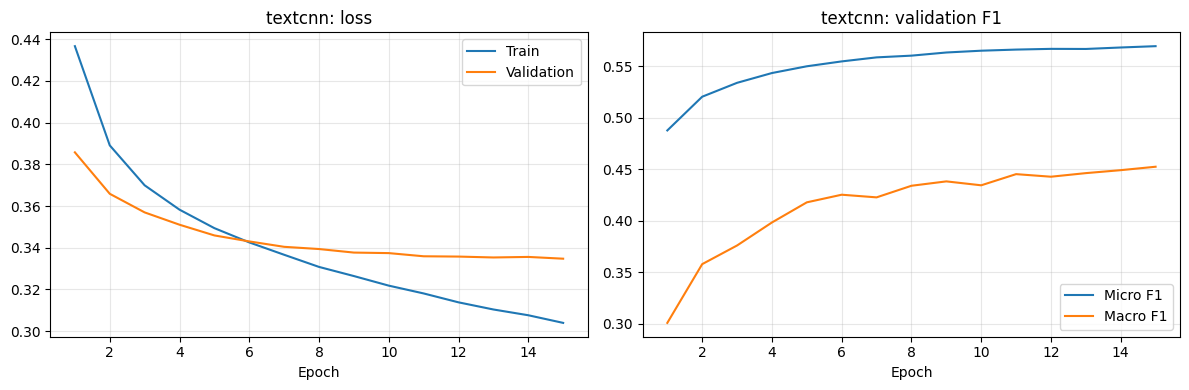

textcnn 기존 → 최종 라벨별 변화


,label_id,label,support,f1_baseline,f1_tuned,precision,recall,f1_change
17,17,부끄러움,286,0.006826,0.006667,0.071429,0.003497,-0.000159
13,13,뿌듯함,656,0.418894,0.425092,0.412017,0.439024,0.006199
23,23,어이없음,2061,0.700697,0.710025,0.588329,0.895197,0.009328
43,43,안심/신뢰,987,0.530498,0.540516,0.495359,0.594732,0.010018
1,1,환영/호의,1121,0.563552,0.574586,0.489335,0.695807,0.011034
8,8,기대감,1387,0.571920,0.584642,0.490005,0.724585,0.012722
3,3,지긋지긋,805,0.400837,0.413675,0.382105,0.450932,0.012838
28,28,즐거움/신남,1273,0.655612,0.670167,0.575536,0.802042,0.014555
6,6,화남/분노,1569,0.684144,0.701551,0.597135,0.850223,0.017408
22,22,짜증,1872,0.705039,0.722696,0.612162,0.881944,0.017657


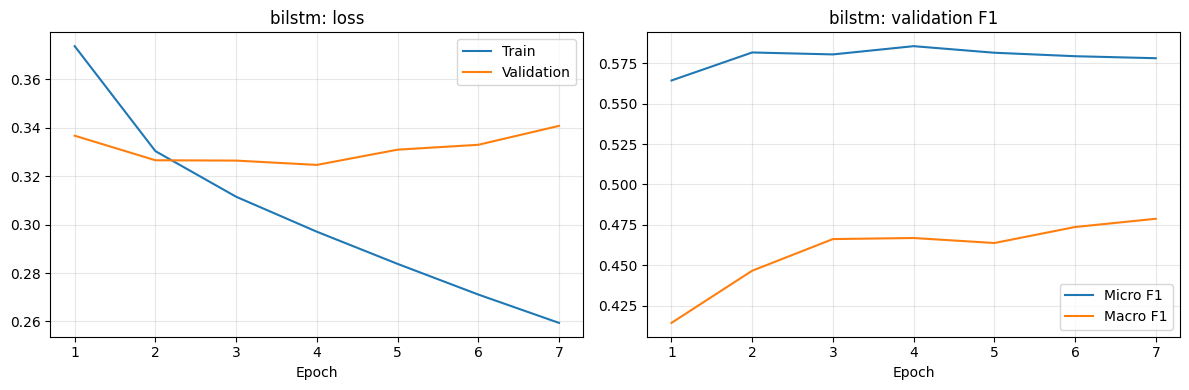

bilstm 기존 → 최종 라벨별 변화


,label_id,label,support,f1_baseline,f1_tuned,precision,recall,f1_change
13,13,뿌듯함,656,0.415315,0.413399,0.445423,0.385671,-0.001916
34,34,경악,695,0.352174,0.366917,0.384252,0.351079,0.014743
20,20,한심함,1497,0.628796,0.643802,0.540345,0.796259,0.015006
23,23,어이없음,2061,0.701818,0.721514,0.642073,0.823387,0.019695
17,17,부끄러움,286,0.000000,0.019802,0.176471,0.010490,0.019802
1,1,환영/호의,1121,0.585130,0.605604,0.570079,0.645852,0.020474
10,10,안타까움/실망,2238,0.700434,0.721263,0.617096,0.867739,0.020829
8,8,기대감,1387,0.580882,0.602713,0.545933,0.672675,0.021831
30,30,죄책감,89,0.000000,0.021978,0.500000,0.011236,0.021978
21,21,역겨움/징그러움,482,0.337102,0.365566,0.423497,0.321577,0.028464


In [ ]:
import matplotlib.pyplot as plt

# 최종 seed 42 후보의 학습 곡선
for name, config in FINAL_CONFIGS.items():
    result = run_experiment(config)
    run_dir = ARTIFACT_DIR / "runs" / result["run_id"]
    history = pd.read_csv(run_dir / "history.csv")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["epoch"], history["train_loss"], label="Train")
    axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
    axes[0].set_title(f"{name}: loss")
    axes[0].legend()

    axes[1].plot(history["epoch"], history["micro_f1"], label="Micro F1")
    axes[1].plot(history["epoch"], history["macro_f1"], label="Macro F1")
    axes[1].set_title(f"{name}: validation F1")
    axes[1].legend()

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(name, "기존 → 최종 라벨별 변화")

    baseline_dir = (
        ARTIFACT_DIR / "runs" /
        baseline_results[name]["run_id"]
    )

    baseline_labels = pd.read_csv(baseline_dir / "labelwise.csv")
    final_labels = pd.read_csv(run_dir / "labelwise.csv")

    comparison = baseline_labels[
        ["label_id", "label", "support", "f1"]
    ].merge(
        final_labels[["label_id", "f1", "precision", "recall"]],
        on="label_id",
        suffixes=("_baseline", "_tuned")
    )

    comparison["f1_change"] = (
        comparison["f1_tuned"] - comparison["f1_baseline"]
    )

    display(comparison.sort_values("f1_change"))
    comparison.to_csv(
        ARTIFACT_DIR / f"{name}_label_changes.csv",
        index=False,
        encoding="utf-8-sig"
    )